# Figure 5 — Interplay between phase mismatch and recoil

* **(a)** Classical upper and lower bounds $\ell_{\max}(\delta_v)$, $\ell_{\min}(\delta_v)$ of the significantly
  populated sidebands as a function of the velocity mismatch $\delta_v=v/v_{\rm ph}-1$ for $a=10^4$, $g=0.1$
  (`pinem_recoil.sideband_limits`, Eqs. for $\ell_{\max}$, $\ell_{\min}$ in the paper).
* **(b–e)** Sideband probabilities $P_\ell(\zeta)$ for $\delta_v=-1,\ 0,\ 1.5,\ 4\,\%$, with the corresponding bounds.
  The upper axis converts $\zeta$ to $z=\zeta v/\omega$ for $\hbar\omega=2$ eV and the electron velocity giving
  $a=10^4$ (≈ 5 keV).

**Data files** (plain-text CSV, see `data/README.md`): `data/fig5/fig5a_bounds.csv` (panel a),
`data/fig5/fig5b_P.csv` … `fig5e_P.csv` (sideband maps, rows $\ell$, columns $\zeta$), `data/fig5/fig5_panels.csv`
($\delta_v$ and bounds of panels b–e) and `data/fig5/fig5_parameters.csv`.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.constants import m_e, c, e, hbar
import pinem_recoil as pr

DATA = Path("data") / "fig5"
FIGS = Path("figures")
DATA.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(exist_ok=True)

RECOMPUTE = False

## Parameters

In [2]:
a = 10000
g = 0.1
photon_energy_eV = 2.0
deltas_v = np.array([-1.0, 0.0, 1.5, 4.0]) / 100     # panels (b)-(e)
zeta_max = 1000
d_zeta = 1
delta_v_curve = np.linspace(-0.05, 0.05, 10000)    # panel (a)

# electron velocity corresponding to a = 1e4 at 2 eV photon energy:
# a = 2 m c^2 gamma (gamma^2 - 1) / (hbar omega)
roots = np.roots([1, 0, -1, -a * photon_energy_eV / (2 * m_e * c**2 / e)])
gamma = np.real(roots[np.isclose(roots.imag, 0) & (roots.real > 1)][0])
v = c * np.sqrt(1 - 1 / gamma**2)
omega = photon_energy_eV * e / hbar
z_um_per_zeta = v / omega * 1e6
print(f"E_kin = {(gamma - 1) * m_e * c**2 / e / 1e3:.2f} keV,  1 unit of zeta = {z_um_per_zeta * 1e3:.2f} nm")

E_kin = 4.93 keV,  1 unit of zeta = 13.60 nm


## Computation

The field-phase step is $d\varphi=-d\zeta\,v_{\rm ph}/v\approx-d\zeta\,(1-\delta_v)$. The truncation is set to the
classical bound plus a margin.

In [3]:
file_a = DATA / "fig5a_bounds.csv"
files_m = [DATA / f"fig5{p}_P.csv" for p in "bcde"]
file_panels = DATA / "fig5_panels.csv"
file_par = DATA / "fig5_parameters.csv"
if RECOMPUTE or not all(f.exists() for f in [file_a, *files_m, file_panels, file_par]):
    lims = np.array([pr.sideband_limits(a, g, dv) for dv in delta_v_curve])
    pr.save_columns(file_a, delta_v=delta_v_curve, l_max=lims[:, 1], l_min=lims[:, 0])
    bounds, truncs = [], []
    for k, dv in enumerate(deltas_v):
        l_lo, l_hi = pr.sideband_limits(a, g, dv)
        l_trunc = int(np.ceil((int(max(abs(l_lo), abs(l_hi))) + 10) / 5) * 5)
        zeta, phi = pr.propagate_steps(a, g, l_trunc, d_zeta, -d_zeta * (1 - dv), zeta_max)
        pr.save_map(files_m[k], np.abs(phi)**2, zeta, pr.sideband_axis(l_trunc), "zeta", "ell")
        bounds.append([l_lo, l_hi]); truncs.append(l_trunc)
    bounds = np.array(bounds)
    pr.save_columns(file_panels, panel=list("bcde"), delta_v=deltas_v, l_min=bounds[:, 0], l_max=bounds[:, 1],
                    l_truncation=truncs)
    pr.save_parameters(file_par, [
        ("a", a, "recoil parameter"),
        ("g", g, "coupling strength"),
        ("d_zeta", d_zeta, "propagation step"),
        ("d_phi", "-d_zeta*(1 - delta_v)", "field-phase step per propagation step"),
        ("photon_energy_eV", photon_energy_eV, "photon energy for the z axis"),
        ("z_um_per_zeta", z_um_per_zeta, "z (um) per unit of zeta"),
    ])
    print("saved", file_a, *files_m, file_panels, file_par)

saved data\fig5\fig5a_bounds.csv data\fig5\fig5b_P.csv data\fig5\fig5c_P.csv data\fig5\fig5d_P.csv data\fig5\fig5e_P.csv data\fig5\fig5_panels.csv data\fig5\fig5_parameters.csv


## Load data and plot

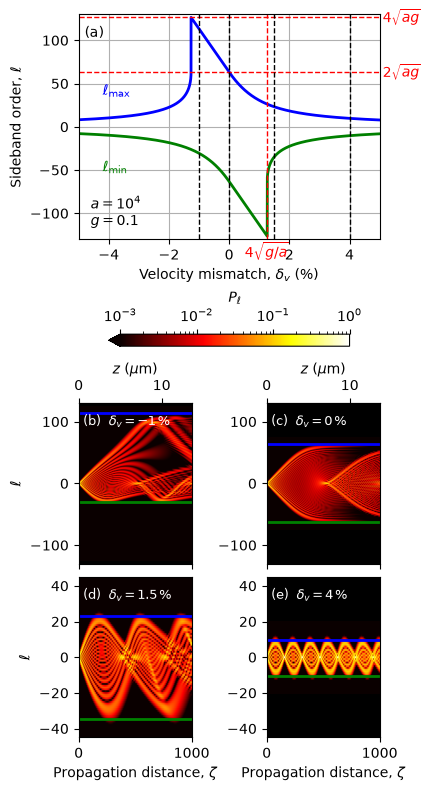

In [4]:
A = pr.load_columns(file_a)
maps = [pr.load_map(f) for f in files_m]       # (zeta, ell, P)
panels = pr.load_columns(file_panels)
cmap = plt.get_cmap("hot").copy()
cmap.set_under(cmap(0.0)); cmap.set_bad(cmap(0.0))

fig = plt.figure(figsize=(4.2, 7.8), constrained_layout=True)
gs = fig.add_gridspec(3, 2, height_ratios=[1.4, 1, 1])
ax_a = fig.add_subplot(gs[0, :])
axs = [fig.add_subplot(gs[1 + k // 2, k % 2]) for k in range(4)]

# (a)
ax_a.plot(A["delta_v"] * 100, A["l_max"], c="blue", lw=2)
ax_a.plot(A["delta_v"] * 100, A["l_min"], c="green", lw=2)
l_ref, dv_ref = np.sqrt(a * g), 4 * np.sqrt(g / a) * 100
for y, lab in [(4 * l_ref, r"$4\sqrt{ag}$"), (2 * l_ref, r"$2\sqrt{ag}$")]:
    ax_a.axhline(y, color="r", ls="--", lw=1)
    ax_a.text(1.01, y, lab, color="r", va="center", transform=ax_a.get_yaxis_transform())
ax_a.axvline(dv_ref, color="r", ls="--", lw=1)
ax_a.text(dv_ref, -133, r"$4\sqrt{g/a}$", color="r", ha="center", va="top")
for dv in panels["delta_v"]:
    ax_a.axvline(dv * 100, color="k", ls="--", lw=1)
ax_a.set_xlim(-5, 5); ax_a.set_ylim(-130, 130); ax_a.grid(True)
ax_a.set_xlabel(r"Velocity mismatch, $\delta_v$ (%)")
ax_a.set_ylabel(r"Sideband order, $\ell$")
ax_a.text(0.02, 0.9, "(a)", transform=ax_a.transAxes)
ax_a.text(0.08, 0.64, r"$\ell_{\max}$", color="blue", transform=ax_a.transAxes)
ax_a.text(0.08, 0.30, r"$\ell_{\min}$", color="green", transform=ax_a.transAxes)
ax_a.text(0.04, 0.06, r"$a=10^4$" + "\n" + rf"$g={g}$", transform=ax_a.transAxes)

# (b)-(e)
bnd = np.maximum(np.abs(panels["l_min"]), np.abs(panels["l_max"]))
ylims = np.ceil((bnd + np.array([15, 15, 10, 8])) / 5) * 5     # bound + margin, rounded
ylims[0:2] = ylims[0:2].max(); ylims[2:4] = ylims[2:4].max()   # same range within each row
for k, ax in enumerate(axs):
    zeta, ell, P = maps[k]
    im = ax.imshow(P, aspect="auto", origin="lower", cmap=cmap, norm=LogNorm(vmin=1e-3, vmax=1),
                   extent=[zeta[0] - 0.5, zeta[-1] + 0.5, ell[0] - 0.5, ell[-1] + 0.5])
    l_lo, l_hi = panels["l_min"][k], panels["l_max"][k]
    ax.axhline(l_lo, color="green", lw=2); ax.axhline(l_hi, color="blue", lw=2)
    ax.set_facecolor("black")
    ax.set_ylim(-ylims[k], ylims[k]); ax.set_xticks([0, zeta_max])
    ax.text(0.04, 0.86, f"({'bcde'[k]})  " + rf"$\delta_v={panels['delta_v'][k] * 100:g}\,\%$",
            color="w", transform=ax.transAxes, fontsize=9)
    if k < 2:
        top = ax.secondary_xaxis("top", functions=(lambda x: x * z_um_per_zeta, lambda x: x / z_um_per_zeta))
        top.set_xlabel(r"$z$ ($\mu$m)")
        ax.set_xticklabels([])
    else:
        ax.set_xlabel(r"Propagation distance, $\zeta$")
    if k % 2 == 0:
        ax.set_ylabel(r"$\ell$")
cb = fig.colorbar(im, ax=axs, orientation="horizontal", extend="min", location="top", shrink=0.8)
cb.set_label(r"$P_\ell$")
fig.savefig(FIGS / "fig5.png", dpi=200)
fig.savefig(FIGS / "fig5.pdf")
plt.show()